**Time Series Classification – Flood Prediction**

Objective

The objective of this experiment is to investigate whether historical environmental conditions and seasonality can improve flood prediction within the next 24 hours at Bahadurabad (SW90), Bangladesh.

Unlike the previous models, this experiment focuses on lagged rainfall, river discharge, soil moisture, and monsoon seasonality rather than current-day environmental values.

I use chronological data splitting to train on older observations and evaluate the model on later years.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report,average_precision_score)

In [2]:
from google.colab import files

uploaded = files.upload()

Saving SW90_Bahadurabad.csv to SW90_Bahadurabad.csv


In [3]:
# Load dataset
df = pd.read_csv("SW90_Bahadurabad.csv")

df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)

In [4]:
print("Dataset shape:", df.shape)
print("Date range:", df["date"].min(), "to", df["date"].max())

display(df.head())

Dataset shape: (3013, 50)
Date range: 2012-12-31 00:00:00 to 2025-12-31 00:00:00


,date,station_id,station_name,rainfall_local_mm,rainfall_upstream_mm,soil_moisture_local,river_discharge_m3s,flood_byStor,rainfall_local_mm_missing,rainfall_upstream_mm_missing,...,flood_within_24h_label_regime,flood_within_48h,flood_within_48h_label_regime,flood_within_72h,flood_within_72h_label_regime,upstream_chain_discharge_lag1d,upstream_reference_discharge_lag2d,upstream_chain_discharge_lag2d,upstream_reference_discharge_lag3d,year
0,2012-12-31,SW90,Bahadurabad,0.0,0.800000,0.043,3774.72,NaN,False,False,...,observed,0.0,observed,0.0,observed,3663.37,NaN,NaN,NaN,2012
1,2013-01-01,SW90,Bahadurabad,0.0,0.000000,0.043,3688.78,NaN,False,False,...,observed,0.0,observed,0.0,observed,3579.96,NaN,NaN,NaN,2013
2,2013-01-02,SW90,Bahadurabad,0.0,1.377778,0.043,3613.10,NaN,False,False,...,observed,0.0,observed,0.0,observed,3506.52,NaN,NaN,NaN,2013
3,2013-01-03,SW90,Bahadurabad,0.2,4.277778,0.044,3555.31,NaN,False,False,...,observed,0.0,observed,0.0,observed,3434.58,NaN,NaN,NaN,2013
4,2013-01-04,SW90,Bahadurabad,0.0,1.644444,0.047,3490.40,NaN,False,False,...,observed,0.0,observed,0.0,observed,3371.87,NaN,NaN,NaN,2013


## Time Series Visualization – River Discharge and Flood Occurrence

Before building the model, I visualize how river discharge changes over time and identify days with positive flood labels.

The graph shows daily river discharge at SW90 Bahadurabad during 2021–2022.

Red markers represent observations labeled as Flood (1).

This visualization helps illustrate the temporal behavior of river discharge and flood labels before model training.

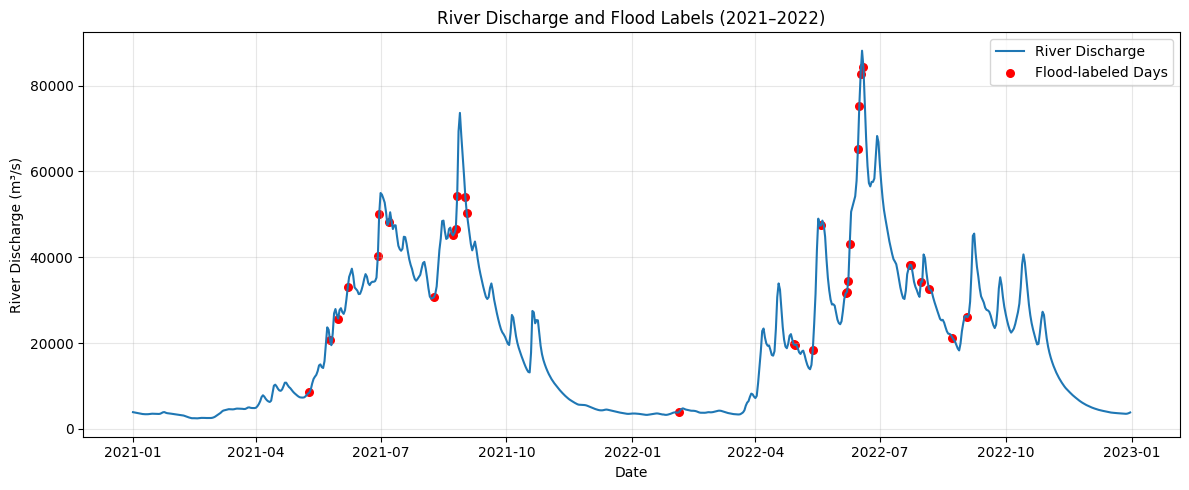

In [5]:
# Select 2021-2022 data for visualization
df_plot = df[df["date"].dt.year.between(2021, 2022)]

# Days with positive flood labels
flood_days = df_plot[df_plot["flood_within_24h"] == 1]

plt.figure(figsize=(12, 5))

# River discharge over time
plt.plot(
    df_plot["date"],
    df_plot["river_discharge_m3s"],
    label="River Discharge")

# Mark flood-labeled days
plt.scatter(
    flood_days["date"],
    flood_days["river_discharge_m3s"],
    color="red",
    label="Flood-labeled Days",
    s=30)

plt.title("River Discharge and Flood Labels (2021–2022)")
plt.xlabel("Date")
plt.ylabel("River Discharge (m³/s)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

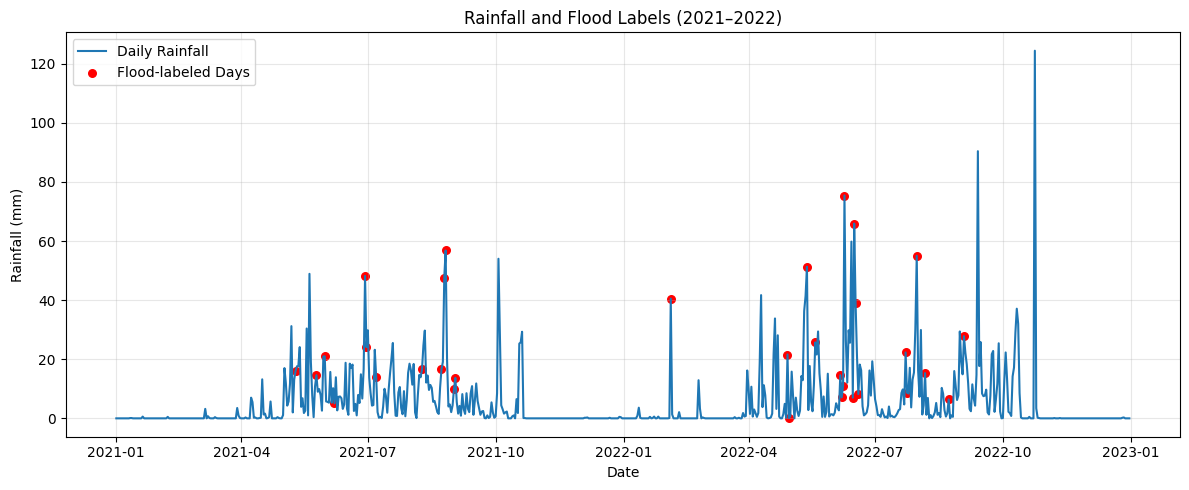

In [6]:
# Select 2021–2022 data
df_plot = df[df["date"].dt.year.between(2021, 2022)]

# Select positive flood-labeled days
flood_days = df_plot[df_plot["flood_within_24h"] == 1]

plt.figure(figsize=(12, 5))

# Daily rainfall
plt.plot(
    df_plot["date"],
    df_plot["rainfall_local_mm"],
    label="Daily Rainfall")

# Mark flood-labeled days
plt.scatter(
    flood_days["date"],
    flood_days["rainfall_local_mm"],
    color="red",
    label="Flood-labeled Days",
    s=30)

plt.title("Rainfall and Flood Labels (2021–2022)")
plt.xlabel("Date")
plt.ylabel("Rainfall (mm)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
missing = df.isnull().sum().sort_values(ascending=False)

missing_percent = (df.isnull().mean() * 100).round(2)

missing_summary = pd.DataFrame({
    "Missing Values": missing,
    "Missing (%)": missing_percent.reindex(missing.index)})

display(missing_summary[missing_summary["Missing Values"] > 0])

,Missing Values,Missing (%)
upstream_chain_discharge_lag2d,3013,100.00
upstream_reference_discharge_lag2d,3013,100.00
upstream_reference_discharge_lag3d,3013,100.00
flood_byStor,2914,96.71
rainfall_local_mm_trend_ratio,727,24.13
rainfall_upstream_mm_trend_ratio,13,0.43
flood_within_72h,2,0.07
flood_within_72h_label_regime,2,0.07
flood_within_48h_label_regime,1,0.03
flood_within_48h,1,0.03


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3013 entries, 0 to 3012
Data columns (total 50 columns):
 #   Column                              Non-Null Count  Dtype         
---  ------                              --------------  -----         
 0   date                                3013 non-null   datetime64[ns]
 1   station_id                          3013 non-null   object        
 2   station_name                        3013 non-null   object        
 3   rainfall_local_mm                   3013 non-null   float64       
 4   rainfall_upstream_mm                3013 non-null   float64       
 5   soil_moisture_local                 3013 non-null   float64       
 6   river_discharge_m3s                 3013 non-null   float64       
 7   flood_byStor                        99 non-null     float64       
 8   rainfall_local_mm_missing           3013 non-null   bool          
 9   rainfall_upstream_mm_missing        3013 non-null   bool          
 10  soil_moisture_local_miss

In [9]:
# Create monsoon indicator
df["monsoon"] = df["date"].dt.month.isin([6, 7, 8, 9]).astype(int)

# Select historical features
features_ts = [
    "rainfall_local_mm_lag1d",
    "rainfall_local_mm_lag3d",
    "rainfall_local_mm_lag5d",
    "river_discharge_m3s_lag1d",
    "river_discharge_m3s_lag3d",
    "river_discharge_m3s_lag5d",
    "soil_moisture_local_lag1d",
    "soil_moisture_local_lag3d",
    "soil_moisture_local_lag5d",
    "monsoon"]

target = "flood_within_24h"

# Split data chronologically
train_df = df[df["date"].dt.year.between(2013, 2015)].copy()
val_df = df[df["date"].dt.year.between(2021, 2022)].copy()
test_df = df[df["date"].dt.year.between(2023, 2025)].copy()

# Prepare X and y
X_train = train_df[features_ts]
y_train = train_df[target].astype(int)

X_val = val_df[features_ts]
y_val = val_df[target].astype(int)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Missing values in training:", X_train.isna().sum().sum())
print("Missing values in validation:", X_val.isna().sum().sum())

Training: (1095, 10)
Validation: (730, 10)
Missing values in training: 0
Missing values in validation: 0


In [10]:
# Keep only the columns needed for our model
df_model = df[["date"] + features_ts + [target]].copy()

# Check dataset
print("Dataset shape:", df_model.shape)
print("Missing values:", df_model.isnull().sum().sum())

display(df_model.head())

Dataset shape: (3013, 12)
Missing values: 0


,date,rainfall_local_mm_lag1d,rainfall_local_mm_lag3d,rainfall_local_mm_lag5d,river_discharge_m3s_lag1d,river_discharge_m3s_lag3d,river_discharge_m3s_lag5d,soil_moisture_local_lag1d,soil_moisture_local_lag3d,soil_moisture_local_lag5d,monsoon,flood_within_24h
0,2012-12-31,0.0,0.0,0.0,3871.58,4082.19,4264.80,0.043,0.044,0.044,0,0.0
1,2013-01-01,0.0,0.0,0.0,3774.72,3970.92,4186.94,0.043,0.044,0.044,0,0.0
2,2013-01-02,0.0,0.0,0.0,3688.78,3871.58,4082.19,0.043,0.043,0.044,0,0.0
3,2013-01-03,0.0,0.0,0.0,3613.10,3774.72,3970.92,0.043,0.043,0.044,0,0.0
4,2013-01-04,0.2,0.0,0.0,3555.31,3688.78,3871.58,0.044,0.043,0.043,0,0.0


## Target and Historical Feature Verification

Before applying expanding window validation, I examine the flood target and check the temporal alignment of historical river discharge features.

The target variable is `flood_within_24h`, where 1 indicates a positive flood label and 0 indicates a negative flood label.

I compare the existing lag features with river discharge values from 1, 3, and 5 calendar days earlier.

This helps verify that the historical predictors are correctly aligned with their dates.

In [11]:
# Check target
print("Flood labels:")
print(df["flood_within_24h"].value_counts())

print("\nLabel regimes:")
print(df["flood_within_24h_label_regime"].value_counts())

# Sort by date
df = df.sort_values("date").reset_index(drop=True)

# Check historical river discharge values
discharge = df.set_index("date")["river_discharge_m3s"]

for days in [1, 3, 5]:

    column = f"river_discharge_m3s_lag{days}d"

    # Value from the exact previous calendar date
    previous_date = df["date"] - pd.Timedelta(days=days)
    expected = previous_date.map(discharge)

    valid = expected.notna()

    matches = ((df.loc[valid, column] - expected[valid]).abs() < 0.02).sum()

    print(f"Lag {days} days: {matches} / {valid.sum()} matches")

Flood labels:
flood_within_24h
0.0    2887
1.0     126
Name: count, dtype: int64

Label regimes:
flood_within_24h_label_regime
observed    3013
Name: count, dtype: int64
Lag 1 days: 3011 / 3011 matches
Lag 3 days: 3007 / 3007 matches
Lag 5 days: 3003 / 3003 matches


## Expanding Window Validation – First Iteration

In this experiment, I use expanding window validation to evaluate flood prediction over time.

In the first iteration, the Logistic Regression model is trained on historical environmental data from 2013–2015 and validated on data from 2021.

The model uses lagged rainfall, river discharge, soil moisture, and monsoon seasonality.

The classification threshold is initially set to 0.5. I evaluate the predictions using precision, recall, F1-score, a confusion matrix, and PR-AUC.

In [12]:
# First expanding window iteration
train = df_model[df_model["date"].dt.year.between(2013, 2015)]
val = df_model[df_model["date"].dt.year == 2021]

# Features and target
X_train = train[features_ts]
y_train = train[target].astype(int)

X_val = val[features_ts]
y_val = val[target].astype(int)

print("Training rows:", len(train))
print("Validation rows:", len(val))
print("Training floods:", y_train.sum())
print("Validation floods:", y_val.sum())

# Create and train the model
model_ts = Pipeline([("scaler", StandardScaler()),("model", LogisticRegression(max_iter=1000))])

model_ts.fit(X_train, y_train)

# Predict on 2021
y_prob = model_ts.predict_proba(X_val)[:, 1]
y_pred = (y_prob >= 0.5).astype(int)

# Evaluation
print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_pred, labels=[0, 1]))

print("\nClassification Report:")
print(classification_report(y_val, y_pred, zero_division=0))

print("PR-AUC:", round(average_precision_score(y_val, y_prob), 3))

Training rows: 1095
Validation rows: 365
Training floods: 73
Validation floods: 13

Confusion Matrix:
[[349   3]
 [  8   5]]

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.98       352
           1       0.62      0.38      0.48        13

    accuracy                           0.97       365
   macro avg       0.80      0.69      0.73       365
weighted avg       0.97      0.97      0.97       365

PR-AUC: 0.334


## Expanding Window Validation – Second Iteration

In the second iteration, I expand the training dataset by including observations from 2021.

The model is now trained on 2013–2015 and 2021, and evaluated on 2022.

This approach allows the model to learn from additional historical observations while preserving chronological order.

I use the same historical features, algorithm, and classification threshold of 0.5 as in the first iteration.

In [13]:
# Second expanding window iteration

# Training: 2013–2015 and 2021
train_2 = df_model[df_model["date"].dt.year.isin([2013, 2014, 2015, 2021])]

# Validation: 2022
val_2 = df_model[df_model["date"].dt.year == 2022]

# Prepare features and target
X_train_2 = train_2[features_ts]
y_train_2 = train_2[target].astype(int)

X_val_2 = val_2[features_ts]
y_val_2 = val_2[target].astype(int)

print("Training rows:", len(train_2))
print("Validation rows:", len(val_2))
print("Training floods:", y_train_2.sum())
print("Validation floods:", y_val_2.sum())

# Train model
model_ts_2 = Pipeline([("scaler", StandardScaler()),("model", LogisticRegression(max_iter=1000))])

model_ts_2.fit(X_train_2, y_train_2)

# Predictions for 2022
y_prob_2 = model_ts_2.predict_proba(X_val_2)[:, 1]
y_pred_2 = (y_prob_2 >= 0.5).astype(int)

# Evaluation
print("\nConfusion Matrix:")
print(confusion_matrix(y_val_2, y_pred_2))

print("\nClassification Report:")
print(classification_report(y_val_2, y_pred_2, zero_division=0))

print("PR-AUC:", round(average_precision_score(y_val_2, y_prob_2), 3))

Training rows: 1460
Validation rows: 365
Training floods: 86
Validation floods: 19

Confusion Matrix:
[[336  10]
 [ 16   3]]

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.97      0.96       346
           1       0.23      0.16      0.19        19

    accuracy                           0.93       365
   macro avg       0.59      0.56      0.58       365
weighted avg       0.92      0.93      0.92       365

PR-AUC: 0.186


## Expanding Window – Effect of Additional Training Data

To investigate whether additional historical observations improve prediction performance, I compare two models on the same validation year (2022).

The first model was trained on 2013–2015, while the second model was trained on 2013–2015 and 2021.

Both models use the same features, algorithm, and classification threshold of 0.5.

This comparison helps evaluate the effect of expanding the training dataset.

In [14]:
# Model 1: trained on 2013–2015
pred_1 = model_ts.predict(X_val_2)
prob_1 = model_ts.predict_proba(X_val_2)[:, 1]

# Model 2: trained on 2013–2015 + 2021
pred_2 = model_ts_2.predict(X_val_2)
prob_2 = model_ts_2.predict_proba(X_val_2)[:, 1]

# Compare both models on 2022
results = pd.DataFrame({
    "Model": ["2013–2015", "2013–2015 + 2021"],
    "Precision": [
        precision_score(y_val_2, pred_1, zero_division=0),
        precision_score(y_val_2, pred_2, zero_division=0)],
    "Recall": [
        recall_score(y_val_2, pred_1, zero_division=0),
        recall_score(y_val_2, pred_2, zero_division=0)],
    "F1-score": [
        f1_score(y_val_2, pred_1, zero_division=0),
        f1_score(y_val_2, pred_2, zero_division=0)],
    "PR-AUC": [
        average_precision_score(y_val_2, prob_1),
        average_precision_score(y_val_2, prob_2)]})

display(results.round(3))

,Model,Precision,Recall,F1-score,PR-AUC
0,2013–2015,0.167,0.211,0.186,0.192
1,2013–2015 + 2021,0.231,0.158,0.188,0.186


## Expanding Window – Third Iteration

In the third iteration, I expand the training dataset to include observations from 2013–2015 and 2021–2022.

The model is evaluated on the following year, 2023.

I keep the same historical environmental features, Logistic Regression algorithm, and classification threshold of 0.5.

The objective is to examine how the model performs on a later year after learning from additional historical observations.

In [15]:
# Third iteration: Training 2013–2015 + 2021–2022
train_3 = df_model[df_model["date"].dt.year.isin([2013, 2014, 2015, 2021, 2022])]

val_3 = df_model[df_model["date"].dt.year == 2023]

# Features and target
X_train_3 = train_3[features_ts]
y_train_3 = train_3[target].astype(int)

X_val_3 = val_3[features_ts]
y_val_3 = val_3[target].astype(int)

print("Training rows:", len(train_3))
print("Evaluation rows:", len(val_3))
print("Training floods:", y_train_3.sum())
print("Evaluation floods:", y_val_3.sum())

# Train model
model_ts_3 = Pipeline([("scaler", StandardScaler()),("model", LogisticRegression(max_iter=1000))])

model_ts_3.fit(X_train_3, y_train_3)

# Predictions
y_prob_3 = model_ts_3.predict_proba(X_val_3)[:, 1]
y_pred_3 = (y_prob_3 >= 0.5).astype(int)

# Evaluation
print("\nConfusion Matrix:")
print(confusion_matrix(y_val_3, y_pred_3, labels=[0, 1]))

print("\nClassification Report:")
print(classification_report(y_val_3, y_pred_3, zero_division=0))

print("PR-AUC:", round(average_precision_score(y_val_3, y_prob_3), 3))

Training rows: 1825
Evaluation rows: 365
Training floods: 105
Evaluation floods: 11

Confusion Matrix:
[[350   4]
 [ 11   0]]

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98       354
           1       0.00      0.00      0.00        11

    accuracy                           0.96       365
   macro avg       0.48      0.49      0.49       365
weighted avg       0.94      0.96      0.95       365

PR-AUC: 0.096


## Expanding Window Validation – Fourth Iteration

In the fourth iteration, the training dataset is expanded to include observations from 2013–2015 and 2021–2023.

The model is evaluated on 2024 using the same historical features, Logistic Regression algorithm, and classification threshold of 0.5.

The objective is to examine how the model performs as more historical observations become available.

In [16]:
# Training: 2013–2015 and 2021–2023
train_4 = df_model[df_model["date"].dt.year.isin([2013, 2014, 2015, 2021, 2022, 2023])]

# Evaluation: 2024
val_4 = df_model[df_model["date"].dt.year == 2024]

X_train_4 = train_4[features_ts]
y_train_4 = train_4[target].astype(int)

X_val_4 = val_4[features_ts]
y_val_4 = val_4[target].astype(int)

print("Training rows:", len(train_4))
print("Evaluation rows:", len(val_4))
print("Training floods:", y_train_4.sum())
print("Evaluation floods:", y_val_4.sum())

# Train model
model_ts_4 = Pipeline([("scaler", StandardScaler()),("model", LogisticRegression(max_iter=1000))])

model_ts_4.fit(X_train_4, y_train_4)

# Predict
y_prob_4 = model_ts_4.predict_proba(X_val_4)[:, 1]
y_pred_4 = (y_prob_4 >= 0.5).astype(int)

# Evaluate
print("\nConfusion Matrix:")
print(confusion_matrix(y_val_4, y_pred_4, labels=[0, 1]))

print("\nClassification Report:")
print(classification_report(y_val_4, y_pred_4, zero_division=0))

print("PR-AUC:", round(average_precision_score(y_val_4, y_prob_4), 3))

Training rows: 2190
Evaluation rows: 366
Training floods: 116
Evaluation floods: 7

Confusion Matrix:
[[356   3]
 [  6   1]]

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.99       359
           1       0.25      0.14      0.18         7

    accuracy                           0.98       366
   macro avg       0.62      0.57      0.58       366
weighted avg       0.97      0.98      0.97       366

PR-AUC: 0.109


## Expanding Window – Fifth Iteration

In the fifth iteration, I expand the training dataset to include observations from 2013–2015 and 2021–2024.

The model is evaluated on 2025 using the same historical environmental features, Logistic Regression algorithm, and classification threshold of 0.5.

This is the final iteration of the expanding window experiment.

The objective is to assess how the model performs on the most recent fully labeled year in the selected dataset.

In [17]:
# Training: 2013–2015 and 2021–2024
train_5 = df_model[df_model["date"].dt.year.isin([2013, 2014, 2015, 2021, 2022, 2023, 2024])]

# Evaluation: 2025
val_5 = df_model[df_model["date"].dt.year == 2025]

# Features and target
X_train_5 = train_5[features_ts]
y_train_5 = train_5[target].astype(int)

X_val_5 = val_5[features_ts]
y_val_5 = val_5[target].astype(int)

print("Training rows:", len(train_5))
print("Evaluation rows:", len(val_5))
print("Training floods:", y_train_5.sum())
print("Evaluation floods:", y_val_5.sum())

# Train model
model_ts_5 = Pipeline([("scaler", StandardScaler()),("model", LogisticRegression(max_iter=1000))])

model_ts_5.fit(X_train_5, y_train_5)

# Predictions
y_prob_5 = model_ts_5.predict_proba(X_val_5)[:, 1]
y_pred_5 = (y_prob_5 >= 0.5).astype(int)

# Evaluation
print("\nConfusion Matrix:")
print(confusion_matrix(y_val_5, y_pred_5, labels=[0, 1]))

print("\nClassification Report:")
print(classification_report(y_val_5, y_pred_5, zero_division=0))

print("PR-AUC:", round(average_precision_score(y_val_5, y_prob_5), 3))

Training rows: 2556
Evaluation rows: 365
Training floods: 123
Evaluation floods: 3

Confusion Matrix:
[[362   0]
 [  3   0]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      1.00       362
           1       0.00      0.00      0.00         3

    accuracy                           0.99       365
   macro avg       0.50      0.50      0.50       365
weighted avg       0.98      0.99      0.99       365

PR-AUC: 0.013


## Expanding Window – Initial Results

I evaluated the Time Series Classification model using expanding window validation from 2021 to 2025.

The model was progressively trained on additional historical observations, while each evaluation used data from a later year.

The best F1-score was achieved in 2021 (0.476), while performance was lower in subsequent years. In 2023 and 2025, the model failed to identify any positive flood-labeled days using the default classification threshold of 0.5.

Across the five evaluation periods, the model correctly identified 9 out of 53 positive flood-labeled days.

These results indicate that the model has limited and inconsistent flood detection performance across years.

As a next step, I will investigate whether adjusting the classification threshold using earlier validation periods can improve recall while controlling false positive predictions.

## Conclusion – Time Series Classification

This experiment applied Logistic Regression to historical rainfall, river discharge, and soil moisture features using an expanding window evaluation strategy.

The results showed inconsistent flood detection performance across different years, with particularly low recall in some evaluation periods.

Threshold tuning did not improve the F1-score, while class weight balancing increased recall at the cost of substantially more false positive predictions.

The analysis also identified limitations in the flood detection labels, which may affect model performance.

Overall, the experiment demonstrates the importance of chronological validation, class imbalance, and data quality when predicting future flood events.

In [18]:
# Validation data
val_2021 = df_model[df_model["date"].dt.year == 2021]
val_2022 = df_model[df_model["date"].dt.year == 2022]

# Actual labels
y_true = np.concatenate([
    val_2021[target].values,
    val_2022[target].values
])

# Predicted probabilities from existing models
prob_2021 = model_ts.predict_proba(
    val_2021[features_ts]
)[:, 1]

prob_2022 = model_ts_2.predict_proba(
    val_2022[features_ts]
)[:, 1]

prob_all = np.concatenate([prob_2021, prob_2022])

# Compare thresholds
results = []

for threshold in [0.2, 0.3, 0.4, 0.5]:

    y_pred = (prob_all >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "TP": tp,
        "FP": fp,
        "FN": fn
    })

threshold_results = pd.DataFrame(results)

display(threshold_results.round(3))

,Threshold,Precision,Recall,F1-score,TP,FP,FN
0,0.2,0.131,0.344,0.190,11,73,21
1,0.3,0.192,0.312,0.238,10,42,22
2,0.4,0.265,0.281,0.273,9,25,23
3,0.5,0.381,0.250,0.302,8,13,24


In [21]:
# Additional time series features
features_ts_plus = features_ts + [
    "rainfall_local_mm",
    "river_discharge_m3s",
    "soil_moisture_local",
    "rainfall_local_mm_sum7d",
    "rainfall_upstream_mm_sum7d",
    "upstream_chain_discharge_lag1d"]

# Use the original SW90 dataset
df_model_plus = df[["date"] + features_ts_plus + [target]].copy()

print("Shape:", df_model_plus.shape)
print("\nMissing values:")
print(df_model_plus.isna().sum())

Shape: (3013, 18)

Missing values:
date                              0
rainfall_local_mm_lag1d           0
rainfall_local_mm_lag3d           0
rainfall_local_mm_lag5d           0
river_discharge_m3s_lag1d         0
river_discharge_m3s_lag3d         0
river_discharge_m3s_lag5d         0
soil_moisture_local_lag1d         0
soil_moisture_local_lag3d         0
soil_moisture_local_lag5d         0
monsoon                           0
rainfall_local_mm                 0
river_discharge_m3s               0
soil_moisture_local               0
rainfall_local_mm_sum7d           0
rainfall_upstream_mm_sum7d        0
upstream_chain_discharge_lag1d    0
flood_within_24h                  0
dtype: int64


### Time Series – Additional Features Experiment

I investigate whether additional environmental features can improve flood prediction.

The expanded feature set includes current-day river discharge, rainfall, soil moisture, seven-day accumulated rainfall, and upstream river discharge.

I retain the same Logistic Regression algorithm, classification threshold of 0.5, and chronological training and validation periods.

The first experiment trains on 2013–2015 and evaluates on 2021, allowing comparison with the original model.

This is an exploratory comparison using a previously evaluated year.

In [22]:
# Training: 2013–2015
train_plus = df_model_plus[
    df_model_plus["date"].dt.year.isin([2013, 2014, 2015])]

# Validation: 2021
val_plus = df_model_plus[
    df_model_plus["date"].dt.year == 2021]

X_train_plus = train_plus[features_ts_plus]
y_train_plus = train_plus[target].astype(int)

X_val_plus = val_plus[features_ts_plus]
y_val_plus = val_plus[target].astype(int)

# Same model, additional features
model_ts_plus = Pipeline([("scaler", StandardScaler()),("model", LogisticRegression(max_iter=1000))])

model_ts_plus.fit(X_train_plus, y_train_plus)

# Predictions
y_prob_plus = model_ts_plus.predict_proba(X_val_plus)[:, 1]
y_pred_plus = (y_prob_plus >= 0.5).astype(int)

# Evaluation
print("Confusion Matrix:")
print(confusion_matrix(y_val_plus, y_pred_plus, labels=[0, 1]))

print("\nClassification Report:")
print(classification_report(y_val_plus, y_pred_plus, zero_division=0))

print("PR-AUC:", round(average_precision_score(y_val_plus, y_prob_plus), 3))

Confusion Matrix:
[[344   8]
 [  6   7]]

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.98      0.98       352
           1       0.47      0.54      0.50        13

    accuracy                           0.96       365
   macro avg       0.72      0.76      0.74       365
weighted avg       0.96      0.96      0.96       365

PR-AUC: 0.53


### Additional Features – Second Iteration (2022)

The expanded Time Series Classification model is trained on observations from 2013–2015 and 2021 and evaluated on 2022.

The same additional environmental features, Logistic Regression algorithm, and classification threshold of 0.5 are maintained.

The objective is to investigate whether the improvement observed in 2021 also appears in another year.

In [23]:
# Training: 2013–2015 and 2021
train_plus_2 = df_model_plus[df_model_plus["date"].dt.year.isin([2013, 2014, 2015, 2021])]

# Evaluation: 2022
val_plus_2 = df_model_plus[df_model_plus["date"].dt.year == 2022]

X_train_plus_2 = train_plus_2[features_ts_plus]
y_train_plus_2 = train_plus_2[target].astype(int)

X_val_plus_2 = val_plus_2[features_ts_plus]
y_val_plus_2 = val_plus_2[target].astype(int)

# Train model
model_ts_plus_2 = Pipeline([("scaler", StandardScaler()),("model", LogisticRegression(max_iter=1000))])

model_ts_plus_2.fit(X_train_plus_2, y_train_plus_2)

# Predictions
y_prob_plus_2 = model_ts_plus_2.predict_proba(X_val_plus_2)[:, 1]
y_pred_plus_2 = (y_prob_plus_2 >= 0.5).astype(int)

# Evaluation
print("Confusion Matrix:")
print(confusion_matrix(y_val_plus_2, y_pred_plus_2, labels=[0, 1]))

print("\nClassification Report:")
print(classification_report(y_val_plus_2, y_pred_plus_2, zero_division=0))

print("PR-AUC:", round(average_precision_score(y_val_plus_2, y_prob_plus_2), 3))

Confusion Matrix:
[[335  11]
 [ 15   4]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.97      0.96       346
           1       0.27      0.21      0.24        19

    accuracy                           0.93       365
   macro avg       0.61      0.59      0.60       365
weighted avg       0.92      0.93      0.92       365

PR-AUC: 0.227


### Additional Features – Third Iteration (2023)

The training dataset is expanded to include observations from 2013–2015 and 2021–2022.

The model is evaluated on 2023 using the same expanded environmental features, Logistic Regression algorithm, and classification threshold of 0.5.

The objective is to investigate whether the expanded feature set improves flood detection in a year where the original model failed to identify positive cases.

This is a retrospective evaluation, as the original results for 2023 have already been examined.

In [24]:
# Training: 2013–2015 and 2021–2022
train_plus_3 = df_model_plus[df_model_plus["date"].dt.year.isin([2013, 2014, 2015, 2021, 2022])]

# Evaluation: 2023
val_plus_3 = df_model_plus[df_model_plus["date"].dt.year == 2023]

X_train_plus_3 = train_plus_3[features_ts_plus]
y_train_plus_3 = train_plus_3[target].astype(int)

X_val_plus_3 = val_plus_3[features_ts_plus]
y_val_plus_3 = val_plus_3[target].astype(int)

# Train model
model_ts_plus_3 = Pipeline([("scaler", StandardScaler()),("model", LogisticRegression(max_iter=1000))])

model_ts_plus_3.fit(X_train_plus_3, y_train_plus_3)

# Predictions
y_prob_plus_3 = model_ts_plus_3.predict_proba(X_val_plus_3)[:, 1]

y_pred_plus_3 = (y_prob_plus_3 >= 0.5).astype(int)

# Evaluation
print("Confusion Matrix:")
print(confusion_matrix(y_val_plus_3, y_pred_plus_3, labels=[0, 1]))

print("\nClassification Report:")
print(classification_report(y_val_plus_3, y_pred_plus_3, zero_division=0))

print("PR-AUC:", round(average_precision_score(y_val_plus_3, y_prob_plus_3), 3))

Confusion Matrix:
[[347   7]
 [ 10   1]]

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.98      0.98       354
           1       0.12      0.09      0.11        11

    accuracy                           0.95       365
   macro avg       0.55      0.54      0.54       365
weighted avg       0.95      0.95      0.95       365

PR-AUC: 0.242


### Additional Features – Fourth Iteration (2024)

The training dataset is expanded to include observations from 2013–2015 and 2021–2023.

The expanded Time Series Classification model is evaluated on 2024 using the same Logistic Regression algorithm and classification threshold of 0.5.

This final main iteration examines whether the additional environmental features continue to improve flood detection in a later year.

The results are interpreted as retrospective evaluation because the original model's performance on 2024 has already been examined.

In [25]:
# Training: 2013–2015 and 2021–2023
train_plus_4 = df_model_plus[
    df_model_plus["date"].dt.year.isin(
        [2013, 2014, 2015, 2021, 2022, 2023])]

# Evaluation: 2024
val_plus_4 = df_model_plus[
    df_model_plus["date"].dt.year == 2024]

X_train_plus_4 = train_plus_4[features_ts_plus]
y_train_plus_4 = train_plus_4[target].astype(int)

X_val_plus_4 = val_plus_4[features_ts_plus]
y_val_plus_4 = val_plus_4[target].astype(int)

# Train model
model_ts_plus_4 = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))])

model_ts_plus_4.fit(X_train_plus_4, y_train_plus_4)

# Predictions
y_prob_plus_4 = model_ts_plus_4.predict_proba(
    X_val_plus_4)[:, 1]

y_pred_plus_4 = (y_prob_plus_4 >= 0.5).astype(int)

# Evaluation
print("Confusion Matrix:")
print(confusion_matrix(y_val_plus_4, y_pred_plus_4, labels=[0, 1]))

print("\nClassification Report:")
print(classification_report(y_val_plus_4, y_pred_plus_4, zero_division=0))

print("PR-AUC:", round(average_precision_score(y_val_plus_4, y_prob_plus_4), 3))

Confusion Matrix:
[[354   5]
 [  5   2]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       359
           1       0.29      0.29      0.29         7

    accuracy                           0.97       366
   macro avg       0.64      0.64      0.64       366
weighted avg       0.97      0.97      0.97       366

PR-AUC: 0.343


## Conclusion – Expanded Time Series Features

The expanded Time Series Classification model was evaluated using an expanding window strategy across 2021–2024.

Additional features included current-day environmental measurements, seven-day accumulated rainfall, and upstream river discharge.

The expanded model achieved higher F1-scores and PR-AUC values in all four evaluation years compared with the original feature set.

Across these evaluation periods, the expanded model correctly identified 14 out of 50 positive flood-labeled days, compared with 9 for the original model. However, false positives also increased from 20 to 31.

These findings suggest that additional environmental and upstream information may improve flood detection, although recall remains limited.

The comparison is exploratory because the evaluation years had already been examined during model development.

The experiment also assumes that current-day measurements are available when making the next-day prediction.

The 2025 results from the original experiment are reported separately due to the very small number of positive flood labels.

### Why Were These Years Selected?

The dataset covers the period from 2012 to 2025, but flood labels are not consistently available across all years.

The GFMS flood detection data are available for two main periods: 2013–March 2016 and 2021–2025.

Some years contain very limited labeled observations. For example, 2012 and 2020 contain only one labeled observation each, while 2016 contains only 90 labeled days.

Therefore, I selected the complete labeled years **2013–2015 and 2021–2025** for the original time series analysis.

A chronological expanding window approach was used to train the model on earlier years and evaluate it on later years, avoiding random mixing of past and future observations.

## Why Focus on 2013–2015 in This Experiment?
The period 2013–2015 contains the highest number of positive flood labels, with 73 flood-labeled days across three years.

This makes it useful for investigating how the model performs during a period with more frequent positive flood detections.

For this additional experiment:

Training: 2013–2014
Evaluation: 2015
This preserves the chronological order of the observations.

The objective is to investigate whether the model performs differently during a period with more positive flood cases, rather than to replace the original expanding window analysis.

In [26]:
# Training: 2013–2014
train_early = df_model_plus[df_model_plus["date"].dt.year.isin([2013, 2014])]

# Evaluation: 2015
val_early = df_model_plus[df_model_plus["date"].dt.year == 2015]

# Features and target
X_train_early = train_early[features_ts_plus]
y_train_early = train_early[target].astype(int)

X_val_early = val_early[features_ts_plus]
y_val_early = val_early[target].astype(int)

print("Training rows:", len(train_early))
print("Evaluation rows:", len(val_early))
print("Training floods:", y_train_early.sum())
print("Evaluation floods:", y_val_early.sum())

# Train model
model_ts_early = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))])

model_ts_early.fit(X_train_early, y_train_early)

# Predictions
y_prob_early = model_ts_early.predict_proba(X_val_early)[:, 1]
y_pred_early = (y_prob_early >= 0.5).astype(int)

# Evaluation
print("\nConfusion Matrix:")
print(confusion_matrix(y_val_early, y_pred_early, labels=[0, 1]))

print("\nClassification Report:")
print(classification_report(y_val_early, y_pred_early, zero_division=0))

print("PR-AUC:", round(
average_precision_score(y_val_early, y_prob_early), 3))

Training rows: 730
Evaluation rows: 365
Training floods: 40
Evaluation floods: 33

Confusion Matrix:
[[310  22]
 [ 16  17]]

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.93      0.94       332
           1       0.44      0.52      0.47        33

    accuracy                           0.90       365
   macro avg       0.69      0.72      0.71       365
weighted avg       0.90      0.90      0.90       365

PR-AUC: 0.546


### High Flood Frequency Period – Results

The model was trained on 2013–2014 and evaluated on 2015, which contained 33 positive flood-labeled days.

The model correctly identified 17 positive cases, achieving a recall of 0.515, an F1-score of 0.472, and a PR-AUC of 0.546.

These results indicate that the model can identify some positive flood cases during a period with more frequent flood detections.

However, 16 positive cases were missed and 22 false alarms were generated.

The findings suggest that model performance varies across different periods, although differences in event frequency and environmental conditions prevent a direct causal conclusion.

In [27]:
# Create discharge change features
df_model_plus["discharge_change_1d"] = (
    df_model_plus["river_discharge_m3s"]
    - df_model_plus["river_discharge_m3s_lag1d"])

df_model_plus["discharge_change_3d"] = (
    df_model_plus["river_discharge_m3s"]
    - df_model_plus["river_discharge_m3s_lag3d"])

# Updated feature list
features_ts_trend = features_ts_plus + [
    "discharge_change_1d",
    "discharge_change_3d"]

print("Number of features:", len(features_ts_trend))
print("Missing values:", df_model_plus[features_ts_trend].isna().sum().sum())

Number of features: 18
Missing values: 0


In [28]:
# Training: 2013–2014
train_trend = df_model_plus[
    df_model_plus["date"].dt.year.isin([2013, 2014])]

# Evaluation: 2015
val_trend = df_model_plus[
    df_model_plus["date"].dt.year == 2015]

# Train model
model_ts_trend = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))])

model_ts_trend.fit(
    train_trend[features_ts_trend],
    train_trend[target].astype(int))

# Predictions
y_prob_trend = model_ts_trend.predict_proba(val_trend[features_ts_trend])[:, 1]

y_pred_trend = (y_prob_trend >= 0.5).astype(int)

# Evaluation
print("Confusion Matrix:")
print(confusion_matrix(
    val_trend[target].astype(int),
    y_pred_trend,
    labels=[0, 1]))

print("\nClassification Report:")
print(classification_report(
    val_trend[target].astype(int),
    y_pred_trend,
    zero_division=0))

print("PR-AUC:", round(
    average_precision_score(
        val_trend[target].astype(int),
        y_prob_trend), 3))

Confusion Matrix:
[[308  24]
 [ 18  15]]

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.93      0.94       332
           1       0.38      0.45      0.42        33

    accuracy                           0.88       365
   macro avg       0.66      0.69      0.68       365
weighted avg       0.89      0.88      0.89       365

PR-AUC: 0.459


### River Discharge Trend – Results

The additional river discharge change features did not improve model performance on the 2015 evaluation period.

The F1-score decreased from 0.472 to 0.417, while PR-AUC decreased from 0.546 to 0.459.

The model also identified fewer positive flood cases and generated more false positives.

These new features were derived from discharge measurements already included in the expanded feature set, so they did not introduce independent information.

Therefore, the previous expanded feature set was retained for the final classification model.

## Seasonal Baseline – June, July and August

To evaluate the effectiveness of the Time Series Classification model, I created a simple seasonal baseline.

The baseline predicts Flood (1) for every day in June, July, and August, and No Flood (0) for all other months.

Unlike the machine learning models, this baseline does not use rainfall, river discharge, soil moisture, or historical environmental features.

The objective is to determine whether the trained model performs better than a simple calendar-based prediction rule.

The baseline is evaluated on the same years used in the Time Series experiments, allowing a comparison of Precision, Recall, F1-score, and false positive predictions.

In [29]:
baseline_results = []

for year in [2015, 2021, 2022, 2023, 2024]:

    test = df_model_plus[
        df_model_plus["date"].dt.year == year
    ]

    y_true = test[target].astype(int)

    # June, July, August = Flood (1)
    y_pred = test["date"].dt.month.isin(
        [6, 7, 8]
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    baseline_results.append({
        "Year": year,
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "TP": tp,
        "FP": fp,
        "FN": fn})

baseline_results = pd.DataFrame(baseline_results)

display(baseline_results.round(3))

,Year,Precision,Recall,F1-score,TP,FP,FN
0,2015,0.239,0.667,0.352,22,70,11
1,2021,0.087,0.615,0.152,8,84,5
2,2022,0.141,0.684,0.234,13,79,6
3,2023,0.065,0.545,0.117,6,86,5
4,2024,0.054,0.714,0.101,5,87,2


# Final Conclusion – Time Series Classification

### Objective

The objective of this analysis was to predict flood detection events within the next 24 hours at the SW90 Bahadurabad station in Bangladesh.

I investigated whether historical rainfall, river discharge, soil moisture, and upstream environmental conditions could help predict future flood detection labels.

### Why Time Series Classification?

Flood prediction depends on environmental conditions that change over time. Therefore, preserving chronological order is important.

Instead of randomly splitting the observations, I used an **Expanding Window approach**, training the model on earlier years and evaluating it on later years.

The analysis focused on complete labeled years from 2013–2015 and 2021–2024. The year 2025 was evaluated separately because it contained only three positive flood labels.

### Model Development

**1. Original Time Series Model**

The initial model used Logistic Regression with historical rainfall, river discharge, and soil moisture lag features (1, 3, and 5 days).

The model showed inconsistent performance across different evaluation years, with particularly low recall in some periods.

**2. Expanded Time Series Model**

I introduced additional features, including current-day measurements, seven-day accumulated rainfall, and upstream river discharge.

The expanded model improved F1-score and PR-AUC across all four retrospective evaluation years from 2021 to 2024 compared with the original feature set.

**3. Threshold and Class Weight Experiments**

Different classification thresholds and class balancing were tested.

Lower thresholds increased recall but generated more false positives.

Class balancing also increased recall but significantly reduced precision and F1-score.

Therefore, the standard Logistic Regression configuration with a classification threshold of 0.5 was retained.

**4. High Flood Frequency Period (2013–2015)**

An additional experiment was performed using 2013–2014 for training and 2015 for evaluation.

The expanded model achieved an F1-score of 0.472, recall of 0.515, and PR-AUC of 0.546.

It correctly identified 17 out of 33 positive flood-labeled days.

Additional river discharge trend features were also tested, but they did not improve the results.

### Seasonal Baseline Comparison

A simple Seasonal Baseline was created to predict Flood (1) during June, July, and August and No Flood (0) during the remaining months.

The baseline achieved higher recall in every evaluated year but generated a large number of false positive predictions.

Across the five evaluation years (2015 and 2021–2024):

| Metric | Seasonal Baseline | Expanded Model |
|---|---:|---:|
| Precision | 0.117 | 0.369 |
| Recall | 0.651 | 0.373 |
| F1-score | 0.199 | 0.371 |
| True Positives | 54 | 31 |
| False Positives | 406 | 53 |

The expanded model substantially reduced false alarms and achieved a higher overall F1-score.

However, the Seasonal Baseline detected more positive cases because it predicted flooding throughout the three summer months.

### Best Performing Approach

**The Expanded Time Series Classification model was the preferred approach among the tested configurations.**

It achieved better F1-scores than the original feature set across the 2021–2024 evaluations and a higher overall F1-score than the Seasonal Baseline across the five evaluated years.

The additional environmental features appear useful for improving model predictions.

However, this comparison is exploratory, since the evaluation years were previously examined during model development.

### Limitations

The dataset contains significantly fewer positive than negative flood labels, creating a class imbalance problem.

Furthermore, flood labels represent detections from available monitoring sources rather than directly measured flooding at the station.

The expanded model also assumes that current-day environmental measurements are available before making the next-day prediction.

Although the expanded model reduced false positives, it still missed many positive flood cases and is not sufficiently reliable for operational flood warning.

### Final Conclusion

This experiment demonstrated the importance of chronological validation, feature engineering, and appropriate baseline comparisons in time series classification.

The expanded feature set produced the strongest overall results among the tested Logistic Regression configurations, particularly in terms of F1-score and reducing false alarms.

However, the Seasonal Baseline achieved higher recall, highlighting the trade-off between detecting more possible flood events and generating unnecessary warnings.

Overall, the project shows that environmental time series data contain useful predictive information, but further improvements in data quality, feature availability, and model evaluation would be necessary before real-world deployment.